# Kabsch structural superposition

Align two sets of matched synthetic coordinates while preserving handedness.

Centre both point clouds, take a singular value decomposition of their cross-covariance and constrain the rotation determinant to +1. Point correspondences are given. RMSD scores the result in the coordinate units.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import kabsch
from scipy.spatial.transform import Rotation

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

RMSD before 3.0272, after 7.82e-16, determinant 1.0000


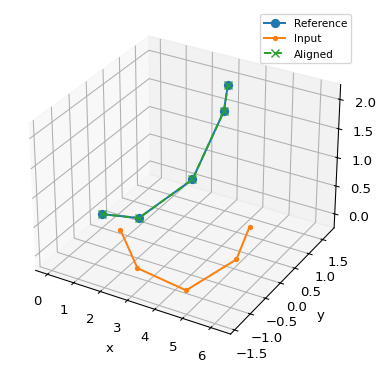

In [2]:
fixed = np.array([[0, 0, 0], [1.2, 0.2, 0], [2.2, 1.1, 0.4], [2.7, 1.7, 1.4], [3.5, 1.1, 2.2]])
moving = fixed @ Rotation.from_euler("xyz", [0.6, -0.4, 0.3]).as_matrix() + [2, -1, 0.5]
aligned, r = kabsch(moving, fixed)
rms = lambda a, b: np.sqrt(np.mean(np.sum((a - b) ** 2, axis=1)))
print(
    f"RMSD before {rms(moving,fixed):.4f}, after {rms(aligned,fixed):.2e}, determinant {np.linalg.det(r):.4f}"
)
assert rms(aligned, fixed) < 1e-10 and np.linalg.det(r) > 0
fig = plt.figure(figsize=(6, 3.8), constrained_layout=True)
ax = fig.add_subplot(projection="3d")
for path, mark, label in [
    (fixed, "o-", "Reference"),
    (moving, ".-", "Input"),
    (aligned, "x--", "Aligned"),
]:
    ax.plot(*path.T, mark, label=label)
ax.set(xlabel="x", ylabel="y", zlabel="z")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The near-zero residual follows from a known rigid transform. Real structural differences remain after rotation and translation.

## Exercise

Mirror the coordinates and explain why the determinant constraint matters.

## References

[Kabsch, least-squares superposition (1976)](https://doi.org/10.1107/S0567739476001873)